# N-Queens Problem (Depth-First Search & Backtracking)

## 1. Problem Overview

The **N-Queens Problem** is one of the most famous benchmark problems in Artificial Intelligence and computer science. First proposed by chess composer Max Bezzel in 1848 for the standard $8 \times 8$ board, it was later generalized to an $N \times N$ board.

It is the quintessential example used to demonstrate **constraint satisfaction**, **state space pruning**, and **Depth-First Search with Backtracking**.

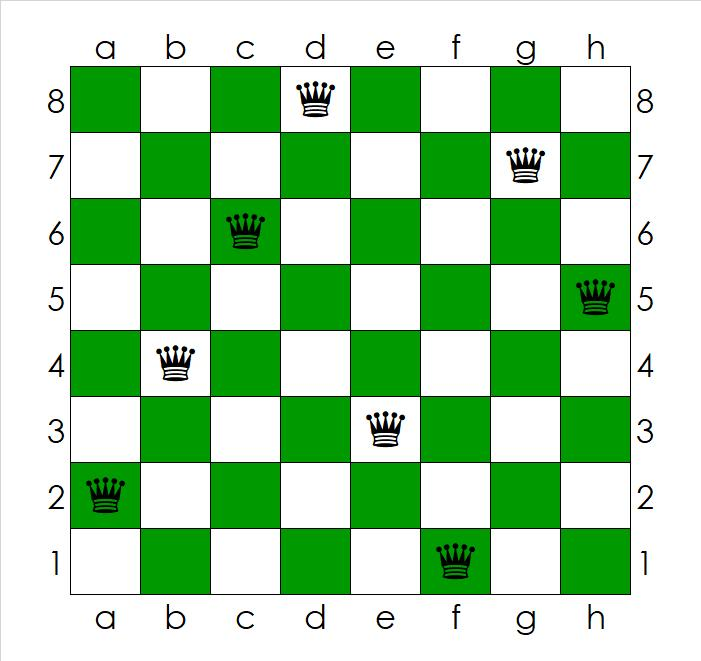

### Problem Statement

- You are given an **$N \times N$ chessboard** and **$N$ chess queens**.
- The objective is to place all $N$ queens on the board such that **no two queens attack each other**.
- In chess, a queen can attack horizontally, vertically, and diagonally across any distance.
- **Constraints:**
  1. **Row Constraint:** No two queens may occupy the same row.
  2. **Column Constraint:** No two queens may occupy the same column.
  3. **Diagonal Constraint:** No two queens may occupy the same diagonal (both major and minor diagonals).

### Learning Objectives

In this notebook, you will learn how to:
1. **Represent an $N \times N$ board** using an efficient 1D row-indexed array.
2. **Formulate diagonal and column constraints** mathematically.
3. **Implement Depth-First Search with Backtracking** to systematically explore and prune the search tree.
4. **Trace the decision tree and backtracking steps** for the 4-Queens problem.
5. **Analyze the exponential time complexity and $\mathcal{O}(N)$ space efficiency** of DFS backtracking.

## 2. State Space Representation & Constraints

### 1D Array Representation

A naive representation would place $N$ queens arbitrarily on an $N \times N$ grid, leading to $\binom{N^2}{N}$ states. For $N = 8$, this requires evaluating over **4.4 billion** configurations!

We can dramatically simplify the problem by noticing that **each row must contain exactly one queen**.

Thus, a state can be represented as a 1D list where the index corresponds to the **row** and the value corresponds to the **column**:

$$\text{state}[\text{row}] = \text{col}$$

For example, in a 4-Queens puzzle, the state `[1, 3, 0, 2]` represents:
- Row 0: Queen at Column 1
- Row 1: Queen at Column 3
- Row 2: Queen at Column 0
- Row 3: Queen at Column 2

> **Advantage:** By construction, no two queens can ever be in the same row! We only need to check columns and diagonals.

### Mathematical Constraint Formulas

Suppose we have placed queens in rows $0, 1, \dots, k-1$, and we wish to place a new queen at $(\text{row}, \text{col})$:

1. **Column Conflict:**
   $$\text{previous\_col} == \text{col}$$

2. **Diagonal Conflict:**
   Two queens at $(r_1, c_1)$ and $(r_2, c_2)$ share a diagonal if and only if the absolute vertical distance equals the absolute horizontal distance:
   $$|r_1 - r_2| == |c_1 - c_2|$$
   - **Major diagonal (slope $+1$):** $r_1 - c_1 == r_2 - c_2$
   - **Minor diagonal (slope $-1$):** $r_1 + c_1 == r_2 + c_2$
   - The absolute value condition $|r_1 - r_2| == |c_1 - c_2|$ elegantly handles **both** diagonals at once!

In [5]:
def dfs(graph: dict, start, goal) -> list | None:
    if start == goal:
        return [start]

    stack = [[start]]
    visited = set()

    while stack:
        path = stack.pop()
        node = path[-1]

        if node in visited:
            continue

        visited.add(node)

        if node == goal:
            return path

        for neighbor in reversed(graph.get(node, [])):
            if neighbor not in visited:
                stack.append(path + [neighbor])

    return None

## 3. Depth-First Search with Backtracking

### How Backtracking Works as DFS

In the N-Queens problem, the state space graph is not pre-built in memory; instead, it forms an **implicit state space tree**:
- **Root:** An empty board (0 queens placed).
- **Depth $k$:** $k$ queens placed safely in the first $k$ rows.
- **Branching:** In row $k$, we evaluate all possible column choices $\text{col} \in \{0, 1, \dots, N-1\}$.
- **Pruning (Dead End):** If placing a queen at $(\text{row}, \text{col})$ threatens any previously placed queen, that entire branch of the search tree is immediately abandoned.
- **Backtracking:** The search unwinds one level to the previous row, removes the queen (`state.pop()`), and continues searching other columns.

This is **Depth-First Search** where the Python call stack serves as the LIFO frontier stack!

In [6]:
def dfs_n_queens(n: int) -> list[list[int]]:
    solutions = []
    state = []

    def backtrack():
        # Base case: All n queens have been placed successfully
        if len(state) == n:
            solutions.append(state.copy())
            return

        row = len(state)

        # Try placing a queen in each column of the current row
        for col in range(n):
            safe = True

            # Check conflicts against all queens placed in previous rows
            for previous_row in range(len(state)):
                previous_col = state[previous_row]
                same_column  = (previous_col == col)
                same_diagonal = (abs(previous_col - col) == abs(previous_row - row))

                if same_column or same_diagonal:
                    safe = False
                    break

            # If position is safe, proceed deeper into the search tree (DFS)
            if safe:
                state.append(col)
                backtrack()
                state.pop()  # Backtrack step: undo move to explore siblings

    backtrack()
    return solutions

## 4. Running DFS & Visualizing Solutions

Let's execute `dfs_n_queens(4)` to find all solutions for the 4-Queens problem.

We also provide an ASCII chessboard formatter to clearly visualize the position of each queen (`Q`) and empty square (`·`).

In [7]:
def format_board(solution: list[int]) -> str:
    n = len(solution)
    lines = []
    lines.append("   " + "   ".join(f"C{c}" for c in range(n)))
    lines.append("  +" + "---+" * n)
    for r, c in enumerate(solution):
        row_str = f"R{r}| " + " | ".join("Q" if col == c else "·" for col in range(n)) + " |"
        lines.append(row_str)
        lines.append("  +" + "---+" * n)
    return "\n".join(lines)

# Find all solutions for 4-Queens
solutions = dfs_n_queens(4)

print(f"Found {len(solutions)} solutions for 4-Queens:")
print(f"Raw column representations: {solutions}\n")

for idx, sol in enumerate(solutions, 1):
    print(f"Solution {idx}: {sol}")
    print(format_board(sol))
    print()

Found 2 solutions for 4-Queens:
Raw column representations: [[1, 3, 0, 2], [2, 0, 3, 1]]

Solution 1: [1, 3, 0, 2]
   C0   C1   C2   C3
  +---+---+---+---+
R0| · | Q | · | · |
  +---+---+---+---+
R1| · | · | · | Q |
  +---+---+---+---+
R2| Q | · | · | · |
  +---+---+---+---+
R3| · | · | Q | · |
  +---+---+---+---+

Solution 2: [2, 0, 3, 1]
   C0   C1   C2   C3
  +---+---+---+---+
R0| · | · | Q | · |
  +---+---+---+---+
R1| Q | · | · | · |
  +---+---+---+---+
R2| · | · | · | Q |
  +---+---+---+---+
R3| · | Q | · | · |
  +---+---+---+---+



## 5. Step-by-Step Execution & Tracing

To see how Depth-First Search prunes illegal branches and discovers solutions, let's trace the complete exploration of the 4-Queens problem.

### Complete 4-Queens Search Tree Trace

The table below traces every decision made by the DFS algorithm:

| Step | Action Taken | Current Placement `state` | Safety Evaluation | Search Decision |
|:---:|:---|:---:|:---|:---|
| **1** | Start search at Row 0 | `[]` | Empty board | Try `col = 0` |
| **2** | Place Queen at $(0, 0)$ | `[0]` | Safe | Advance to Row 1 |
| **3** | Try $(1, 0)$ and $(1, 1)$ | `[0]` | Conflict: $(1, 0)$ shares column; $(1, 1)$ shares diagonal | Pruned |
| **4** | Place Queen at $(1, 2)$ | `[0, 2]` | Safe | Advance to Row 2 |
| **5** | Try all columns in Row 2 | `[0, 2]` | Conflicts with all columns $0, 1, 2, 3$ | **Dead End $\implies$ Backtrack to Row 1!** |
| **6** | Place Queen at $(1, 3)$ | `[0, 3]` | Safe | Advance to Row 2 |
| **7** | Place Queen at $(2, 1)$ | `[0, 3, 1]` | Safe | Advance to Row 3 |
| **8** | Try all columns in Row 3 | `[0, 3, 1]` | Conflicts with all columns $0, 1, 2, 3$ | **Dead End $\implies$ Backtrack to Row 0!** |
| **9** | Place Queen at $(0, 1)$ | `[1]` | Safe | Advance to Row 1 |
| **10** | Place Queen at $(1, 3)$ | `[1, 3]` | Safe | Advance to Row 2 |
| **11** | Place Queen at $(2, 0)$ | `[1, 3, 0]` | Safe | Advance to Row 3 |
| **12** | Place Queen at $(3, 2)$ | `[1, 3, 0, 2]` | All 4 queens placed safely! | **⭐ SOLUTION 1 FOUND! ⭐** |
| **13** | Backtrack to Row 0; try $(0, 2)$ | `[2]` | Safe | Advance to Row 1 |
| **14** | Place Queen at $(1, 0)$ | `[2, 0]` | Safe | Advance to Row 2 |
| **15** | Place Queen at $(2, 3)$ | `[2, 0, 3]` | Safe | Advance to Row 3 |
| **16** | Place Queen at $(3, 1)$ | `[2, 0, 3, 1]` | All 4 queens placed safely! | **⭐ SOLUTION 2 FOUND! ⭐** |
| **17** | Backtrack to Row 0; try $(0, 3)$ | `[3]` | Mirror of branch `[0]`; leads to dead ends | **Search tree fully explored.** |

> **Key Insight:** Notice how backtracking pruned massive subtrees! Out of $4^4 = 256$ possible column combinations, the algorithm evaluated only **17 node states** to find both solutions.

## 6. Scaling Up: The Classic 8-Queens Problem

Let's test our DFS implementation on the classic **8-Queens puzzle** ($8 \times 8$ chessboard).

In [8]:
solutions_8 = dfs_n_queens(8)

print(f"Total solutions found for 8-Queens: {len(solutions_8)}\n")
print(f"Displaying First Solution: {solutions_8[0]}")
print(format_board(solutions_8[0]))

Total solutions found for 8-Queens: 92

Displaying First Solution: [0, 4, 7, 5, 2, 6, 1, 3]
   C0   C1   C2   C3   C4   C5   C6   C7
  +---+---+---+---+---+---+---+---+
R0| Q | · | · | · | · | · | · | · |
  +---+---+---+---+---+---+---+---+
R1| · | · | · | · | Q | · | · | · |
  +---+---+---+---+---+---+---+---+
R2| · | · | · | · | · | · | · | Q |
  +---+---+---+---+---+---+---+---+
R3| · | · | · | · | · | Q | · | · |
  +---+---+---+---+---+---+---+---+
R4| · | · | Q | · | · | · | · | · |
  +---+---+---+---+---+---+---+---+
R5| · | · | · | · | · | · | Q | · |
  +---+---+---+---+---+---+---+---+
R6| · | Q | · | · | · | · | · | · |
  +---+---+---+---+---+---+---+---+
R7| · | · | · | Q | · | · | · | · |
  +---+---+---+---+---+---+---+---+


## 7. Complexity Analysis

### Number of Solutions by Board Size ($N$)

| $N$ | Total Possible Placements ($N^N$) | Total Valid Solutions | Number of Distinct Fundamental Solutions |
|:---:|:---:|:---:|:---:|
| **1** | $1$ | **1** | 1 |
| **2** | $4$ | **0** | 0 (No solution exists) |
| **3** | $27$ | **0** | 0 (No solution exists) |
| **4** | $256$ | **2** | 1 |
| **5** | $3,125$ | **10** | 2 |
| **6** | $46,656$ | **4** | 1 |
| **7** | $823,543$ | **40** | 6 |
| **8** | $16,777,216$ | **92** | 12 |
| **9** | $387,420,489$ | **352** | 46 |
| **10** | $10,000,000,000$ | **724** | 92 |

### Time Complexity

- **Theoretical Upper Bound:** $\mathcal{O}(N!)$
  - The first queen has $N$ choices, the second at most $N - 1$, the third at most $N - 2$, etc.
- In practice, diagonal constraint pruning discards vast subtrees early, making actual execution vastly faster than brute-force exploration.

### Space Complexity

- **Linear Auxiliary Space:** $\mathcal{O}(N)$
  - The recursion stack reaches a maximum depth of $N$.
  - The `state` list stores at most $N$ integers.
- This $\mathcal{O}(N)$ memory footprint is why **DFS / Backtracking** is universally chosen over **BFS** for constraint satisfaction problems (BFS would require storing $\mathcal{O}(b^N)$ partial boards in memory).